Missingness Correlation Matrix:
                           age_missing  gender_missing  \
age_missing                        NaN             NaN   
gender_missing                     NaN             NaN   
chief_complaint_missing            NaN             NaN   
saturation_mcar_missing            NaN             NaN   
saturation_mar_missing             NaN             NaN   
saturation_mnar_missing            NaN             NaN   
mortality_30_days_missing          NaN             NaN   

                           chief_complaint_missing  saturation_mcar_missing  \
age_missing                                    NaN                      NaN   
gender_missing                                 NaN                      NaN   
chief_complaint_missing                        NaN                      NaN   
saturation_mcar_missing                        NaN                 1.000000   
saturation_mar_missing                         NaN                -0.019085   
saturation_mnar_missing      

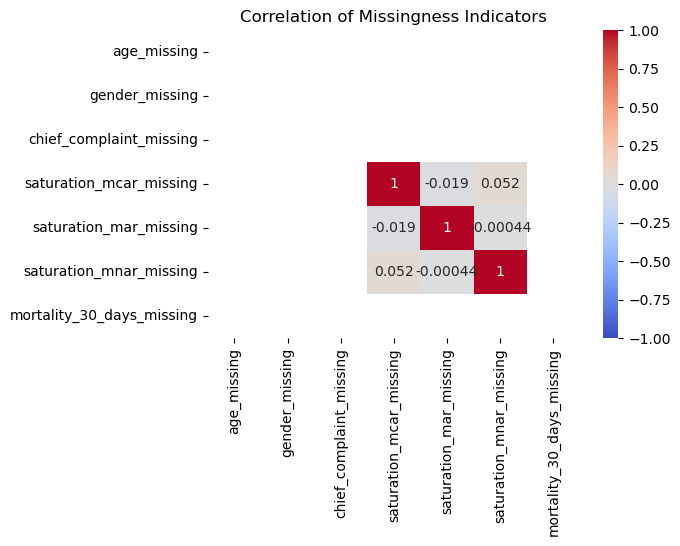

In [1]:
from os import path

import numpy as np
import pandas as pd
import statsmodels.api as sm

# Optional visualization using seaborn
import matplotlib.pyplot as plt
import seaborn as sns
import os
import pathlib as pl

repo_root = pl.Path.cwd()
if repo_root.name == "bayesian_examples":
    repo_root = repo_root.parent
data_path = repo_root / "data" / "healthcare_dataset_2_missingness.csv"
df = pd.read_csv(data_path).copy()

# Create a binary missingness indicator dataframe
missing_df = df.isna().astype(int)
missing_df.columns = [f"{col}_missing" for col in df.columns]

# Calculate correlation between missingness indicators
missing_corr = missing_df.corr()
print("Missingness Correlation Matrix:")
print(missing_corr)



plt.figure(figsize=(6, 4))
sns.heatmap(missing_corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation of Missingness Indicators")
plt.show()

In [2]:
# Set income missingness as the target variable (1 = missing, 0 = observed)
y = df["saturation_mnar"].isna().astype(int)
df['gender'] = df['gender'].astype('category').cat.codes  # Convert gender to numeric codes
df['chief_complaint'] = df['chief_complaint'].astype('category').cat.codes  # Convert chief_complaint to numeric codes
# Use other observed features as predictors (drop the target column itself)
X = df[["age", "gender", "chief_complaint"]].copy()
X = sm.add_constant(X)  # Add intercept

# Fit logistic regression
logit_model = sm.Logit(y, X).fit(disp=False)
print(logit_model.summary())

                           Logit Regression Results                           
Dep. Variable:        saturation_mnar   No. Observations:                  400
Model:                          Logit   Df Residuals:                      396
Method:                           MLE   Df Model:                            3
Date:                Mon, 19 Oct 2026   Pseudo R-squ.:                0.006994
Time:                        13:13:52   Log-Likelihood:                -157.21
converged:                       True   LL-Null:                       -158.31
Covariance Type:            nonrobust   LLR p-value:                    0.5291
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
const              -1.5806      0.461     -3.429      0.001      -2.484      -0.677
age                 0.0014      0.007      0.200      0.842      -0.012       0.015
gender             -0.1078      

## Theory: testing whether missingness is MNAR

**Setup.** Let $R_i = 1$ when value $i$ is missing (0 otherwise), $Y_i$ be the variable of interest (here: saturation), and $X_i$ other observed columns (age, gender, ...).

### The three missingness mechanisms

**MCAR — Missing Completely At Random**

$$P(R_i = 1 \mid Y_i, X_i) = P(R_i = 1)$$

Missingness is unrelated to anything at all. Dropping incomplete rows is harmless (just loses power).

**MAR — Missing At Random**

$$P(R_i = 1 \mid Y_i, X_i) = P(R_i = 1 \mid Y_i^{\text{obs}}, X_i)$$

Missingness may depend on things you *can see* (observed values and covariates) but not on the missing value itself. This is testable with your data: regress $R$ on the observed covariates — exactly what **cell 1** does (logistic regression of `isna(saturation_mnar)` on age, gender, chief complaint).

**MNAR — Missing Not At Random**

$$P(R_i = 1 \mid Y_i, X_i) \text{ depends on } Y_i^{\text{mis}}$$

Whether a value is missing depends on the value's own magnitude — the one thing you never get to observe. Example: a patient's saturation is not recorded *because* it was dangerously low.

### Why MNAR is usually undetectable

MAR and MNAR models are **observationally equivalent**: for any MAR explanation of the observed data there exists an MNAR explanation producing exactly the same distribution of observed data. From a single column with holes, you literally cannot tell the two apart.

> **Analogy.** A student answers exam questions but skips the ones they got wrong. You only see the answered questions. From the answer sheet alone you cannot distinguish "skipped at random" from "skipped the wrong ones" — the skipped answers are precisely what you'd need to check.

### The trick used here: replicate measurements

`saturation_mcar`, `saturation_mar` and `saturation_mnar` are the **same underlying saturation** with three different missingness masks applied (they are exactly equal wherever both are observed). So wherever *another* column is observed, it reveals the true value of the row the tested column is missing:

$$\tilde{Y}_i = \text{mean of the other two columns} \approx Y_i \quad \text{(the "hidden" value, now visible)}$$

With a proxy for the unobserved value, MNAR becomes testable.

### The model

For each column, a Bayesian logistic regression of the missingness indicator on the standardized proxy $\tilde{z}_i$:

$$R_i \sim \text{Bernoulli}(p_i), \qquad
\text{logit}(p_i) = \ln\!\frac{p_i}{1-p_i} = \alpha + \beta_{\text{proxy}}\,\tilde{z}_i$$

with priors $\alpha \sim \text{Normal}(-1.5,\ 2)$ (a baseline missing rate around 15%) and $\beta_{\text{proxy}} \sim \text{Normal}(0,\ 1)$.

**Decision rule — the 94% HDI (highest density interval) of** $\beta_{\text{proxy}}$:

| posterior of $\beta_{\text{proxy}}$ | conclusion |
|---|---|
| interval **includes 0** | missingness independent of the true value → compatible with **MAR/MCAR** |
| interval **excludes 0** | missingness depends on the unobserved value → **MNAR evidence** |
| **negative** (as here) | *low* values are preferentially missing — the clinically dangerous direction |

Effect size in odds ratios: $\exp(\beta)$ is the factor by which the odds of missingness multiply per 1-SD **increase** in the true value. E.g. $\beta = -0.81 \Rightarrow e^{-0.81} \approx 0.44$: each 1-SD higher saturation cuts the odds of being missing by more than half.

### Dumbed down

**The question:** *do numbers go missing **because** of what the numbers are?*

**How we answer:** for every row we sneak a peek at the true number through the replicate columns, then ask: *were rows with low true numbers more often the missing ones?*

- Yes → the data is hiding values *because* they look bad → **MNAR**.
- No → missingness has nothing to do with the value itself → **MAR or MCAR** (check the covariates in cell 1 to tell those two apart).

Instead of a single p-value we get a full posterior distribution for $\beta$: if its 94% credible interval does not touch zero, we call it.

**Caveat:** this works only because we have replicate columns. With one lonely column and no correlated observed surrogate, MAR vs MNAR is **not decidable** from the data — you would then do *sensitivity analysis* (shift all imputations by a value $\delta$ and report where your conclusions flip) instead of testing.


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha, beta_proxy]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 6 seconds.
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha, beta_proxy]


===== saturation_mcar =====
              mean     sd hdi94_lb hdi94_ub ess_bulk ess_tail r_hat mcse_mean mcse_sd
alpha       -1.627  0.154     -1.9     -1.3     3848     2589  1.00    0.0025  0.0025
beta_proxy  -0.032  0.154    -0.31     0.26     3547     2880  1.00    0.0026  0.0023
max r_hat: 1.0027372130570429 | divergences: 0


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 6 seconds.
Initializing NUTS using jitter+adapt_diag...


===== saturation_mar =====
              mean     sd hdi94_lb hdi94_ub ess_bulk ess_tail r_hat mcse_mean mcse_sd
alpha       -1.944  0.179     -2.3     -1.6     2834     2389  1.00    0.0034  0.0028
beta_proxy   0.329  0.209   -0.052     0.74     2748     2612  1.00     0.004  0.0031
max r_hat: 1.0014682254929195 | divergences: 0


Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha, beta_proxy]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 6 seconds.


===== saturation_mnar =====
              mean     sd hdi94_lb hdi94_ub ess_bulk ess_tail r_hat mcse_mean mcse_sd
alpha       -2.203   0.21     -2.6     -1.8     1995     2337  1.00    0.0047  0.0031
beta_proxy  -0.813  0.162     -1.1    -0.52     1845     2149  1.00    0.0038  0.0026
max r_hat: 1.0027076149143563 | divergences: 0

Does missingness depend on the (unobserved) true value? [94% HDI of beta_proxy]
     saturation_mcar: beta = -0.03, 94% HDI [-0.31, +0.26]  no -> consistent with MAR/MCAR
      saturation_mar: beta = +0.33, 94% HDI [-0.05, +0.74]  no -> consistent with MAR/MCAR
     saturation_mnar: beta = -0.81, 94% HDI [-1.12, -0.52]  YES -> MNAR evidence


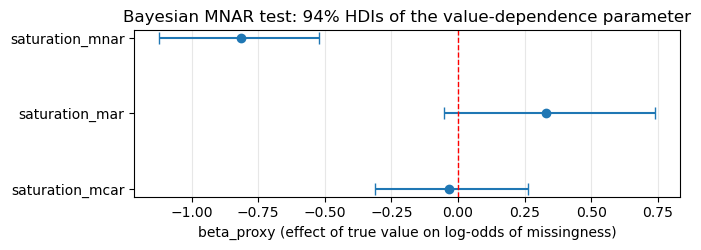

In [3]:
import arviz as az
import pymc as pm

SEED = 42
TARGETS = ["saturation_mcar", "saturation_mar", "saturation_mnar"]

# The three saturation columns are replicate measurements of the SAME underlying
# value, so the other two columns reveal the true saturation wherever observed.
# If missingness of a column depends on that true value, the mechanism is MNAR.
# Bayesian logistic model per column:
#   r ~ Bernoulli(sigmoid(alpha + beta_proxy * standardized true value))

beta_summaries = {}

for col in TARGETS:
    others = [c for c in TARGETS if c != col]
    rows = df[others].notna().all(axis=1)

    proxy = df.loc[rows, others].mean(axis=1).to_numpy()
    r = df.loc[rows, col].isna().astype(int).to_numpy()
    proxy_z = (proxy - proxy.mean()) / proxy.std()

    with pm.Model():
        alpha = pm.Normal("alpha", mu=-1.5, sigma=2.0)
        beta_proxy = pm.Normal("beta_proxy", mu=0.0, sigma=1.0)
        p_missing = pm.math.sigmoid(alpha + beta_proxy * proxy_z)
        pm.Bernoulli("missingness", p=p_missing, observed=r)

        idata = pm.sample(draws=1000, tune=1000, chains=4, target_accept=0.9,
                          random_seed=SEED, progressbar=False)

    summary = az.summary(idata, var_names=["alpha", "beta_proxy"],
                         ci_prob=0.94, ci_kind="hdi")
    print(f"===== {col} =====")
    print(summary)
    print("max r_hat:", summary["r_hat"].max(),
          "| divergences:", int(idata.sample_stats["diverging"].sum()))
    beta_summaries[col] = summary.loc["beta_proxy"]

# --- Verdict: is the missingness mechanism MNAR? ---
print("\nDoes missingness depend on the (unobserved) true value? [94% HDI of beta_proxy]")
for col, row in beta_summaries.items():
    lo, hi = row["hdi94_lb"], row["hdi94_ub"]
    verdict = "YES -> MNAR evidence" if (lo > 0 or hi < 0) else "no -> consistent with MAR/MCAR"
    print(f"  {col:>18}: beta = {row['mean']:+.2f}, 94% HDI [{lo:+.2f}, {hi:+.2f}]  {verdict}")

# Forest plot of the value-dependence effect across the three mechanisms
fig, ax = plt.subplots(figsize=(7, 2.6))
for i, (col, row) in enumerate(beta_summaries.items()):
    m, lo, hi = row["mean"], row["hdi94_lb"], row["hdi94_ub"]
    ax.errorbar(m, i, xerr=[[m - lo], [hi - m]], fmt="o", color="C0", capsize=4)
ax.axvline(0, color="red", linestyle="--", linewidth=1)
ax.set_yticks(range(len(TARGETS)))
ax.set_yticklabels(TARGETS)
ax.set_xlabel("beta_proxy (effect of true value on log-odds of missingness)")
ax.set_title("Bayesian MNAR test: 94% HDIs of the value-dependence parameter")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()
